# Power analysis GWAS synthetic data with additive effect

In [2172]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats

In [2173]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [2174]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '38_9_120_38_maf_0.048_0.05.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [2175]:
#wanted_maf = '0.01_0.01'
#wanted_maf = '0.024_0.025'
#wanted_maf = '0.048_0.05'
#wanted_maf = '0.49_0.49'
wanted_maf = '0.1_0.1'
#wanted_maf = '0.25_0.25'

In [2176]:
snps = [f for f in os.listdir('./data/genotype') if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)

./data/genotype/60_2_120_60_maf_0.1_0.1.pkl


In [2177]:
geno = pd.read_pickle(path_snp)
i = 0

In [2178]:
geno[geno.columns[i]].value_counts()
num_maj = geno[geno.columns[i]].value_counts()[1]
num_het = geno[geno.columns[i]].value_counts()[0]
try:
    num_min = geno[geno.columns[i]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min

In [2179]:
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.10263578274760383

In [2180]:
mean_min_H0 = 0
mean_het_H0 = 0
mean_maj_H0 = 0

In [2226]:
true_mean = 160
true_effect = 5
true_sd = 40

In [2182]:
mean_min = true_mean - true_effect
mean_het = true_mean
mean_maj = true_mean + true_effect
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[i]]), "pheno": pheno})

In [2183]:
df_pheno

,geno,pheno
0,1,165.842642
1,1,165.459904
2,1,164.060001
3,1,165.501338
4,1,166.239836
...,...,...
2499,0,160.166634
2500,1,163.953952
2501,0,159.821058
2502,1,166.782313


<AxesSubplot:xlabel='geno', ylabel='pheno'>

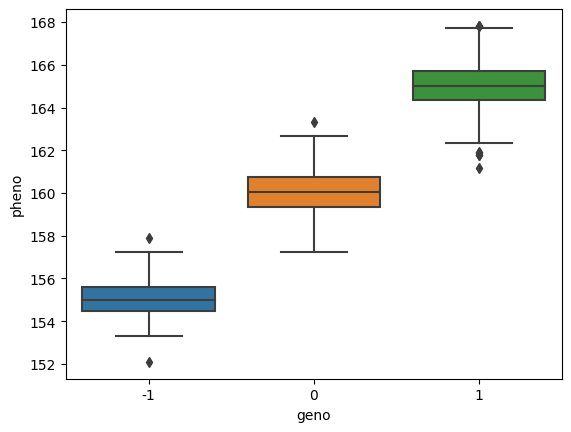

In [2184]:
sns.boxplot(data=df_pheno, x="geno", y="pheno")

In [2185]:
def standy(pandasdf):
    print(stats.tstd(pandasdf))
    return (pandasdf - pandasdf.mean())/stats.tstd(pandasdf)

In [2186]:
X = df_pheno[['geno']]
y = df_pheno[['pheno']]

In [2187]:
#y = standy(df_pheno[['pheno']])
#X = standy(df_pheno[['geno']])
#df_pheno['std_geno'] = X
#df_pheno['std_pheno'] = y

In [2188]:
df_pheno

,geno,pheno
0,1,165.842642
1,1,165.459904
2,1,164.060001
3,1,165.501338
4,1,166.239836
...,...,...
2499,0,160.166634
2500,1,163.953952
2501,0,159.821058
2502,1,166.782313


In [2189]:
reg = LinearRegression().fit(X, y)

In [2190]:
reg.score(X, y)

0.8501066302629984

In [2191]:
estimated_effect = reg.coef_[0][0]
estimated_effect

4.971284085271449

In [2192]:
estimated_intercept = reg.intercept_[0]
estimated_intercept

160.04498309144807

In [2193]:
def find_lin_reg(X):
    y = reg.coef_[0][0]*X + reg.intercept_[0]
    return y

In [2194]:
find_lin_reg(1)

165.0162671767195

In [2195]:
estimated_effect

/home/mat2m10/.pyenv/versions/3.10.6/envs/ctg/lib/python3.10/site-packages/IPython/core/displayhook.py:275: UserWarning: Output cache limit (currently 1000 entries) hit.
Flushing oldest 200 entries.
  warn('Output cache limit (currently {sz} entries) hit.\n'


4.971284085271449

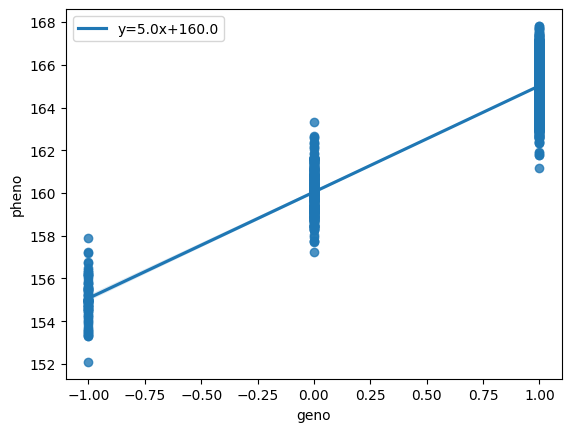

In [2196]:
# use line_kws to set line label for legend
ax = sns.regplot(x="geno", y="pheno", data=df_pheno, 
 line_kws={'label':"y={0:.1f}x+{1:.1f}".format(estimated_effect,estimated_intercept)})

# plot legend
ax.legend()

plt.show()

In [2197]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b

print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")
p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = residual_sum_of_squares['pheno'].pheno / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat

SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

var = [0.00149681 0.00174164]
sd = [0.03868864 0.04173298]
t_square = [4136.74408737  119.1212228 ]
SE(beta_hat[0]): 0.03868863524340601
SE(beta_hat[1]): 0.04173298400252782


In [2198]:
p_values

[0.0, 0.0]

# Power

In [2199]:
total_humans

2504

In [2200]:
maf

0.10263578274760383

In [2201]:
number_of_tests = 5000

In [2202]:
alt = estimated_effect
alt

4.971284085271449

In [2203]:
X

,geno
0,1
1,1
2,1
3,1
4,1
...,...
2499,0
2500,1
2501,0
2502,1


## create random phenotype with no link to the genotype

In [2204]:
mean_min = true_mean
mean_het = true_mean
mean_maj = true_mean
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno['pheno_null'] = pheno

In [2205]:
df_pheno

,geno,pheno,pheno_null
0,1,165.842642,159.744483
1,1,165.459904,160.637174
2,1,164.060001,160.708575
3,1,165.501338,159.117927
4,1,166.239836,160.316471
...,...,...,...
2499,0,160.166634,159.330157
2500,1,163.953952,159.404496
2501,0,159.821058,159.425165
2502,1,166.782313,160.713205


In [2206]:
# SE under nul hypothesis
X = df_pheno[['geno']]
y = df_pheno[['pheno_null']]
reg = LinearRegression().fit(X, y)

In [2207]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b
print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")

p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = 1['pheno_null'].pheno_null / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat
SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

var = [0.00146835 0.00170853]
sd = [0.03831905 0.04133432]
t_square = [ 4.17570875e+03 -7.91898780e-01]
SE(beta_hat[0]): 0.03831905044660921
SE(beta_hat[1]): 0.04133431715074408


In [2208]:
SE[1]

0.04133431715074408

In [2209]:
distribution_nul = np.random.normal(0, SE[1], 5000)
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)
labels = ['nul hypothesis']*len(distribution_nul) + ['alternate hypothesis'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z": list(distribution_nul)+list(distribution_alt), 'labels': labels})

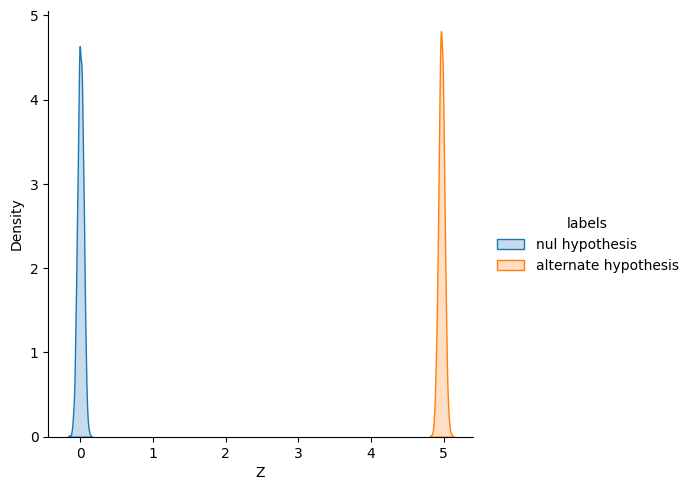

In [2210]:
sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)

In [2211]:
distribution_nul = np.random.normal(0, SE[1], 5000)**2
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)**2
labels = ['nul hypothesis']*len(distribution_nul) + ['alternate hypothesis'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z2": list(distribution_nul)+list(distribution_alt), 'labels': labels})

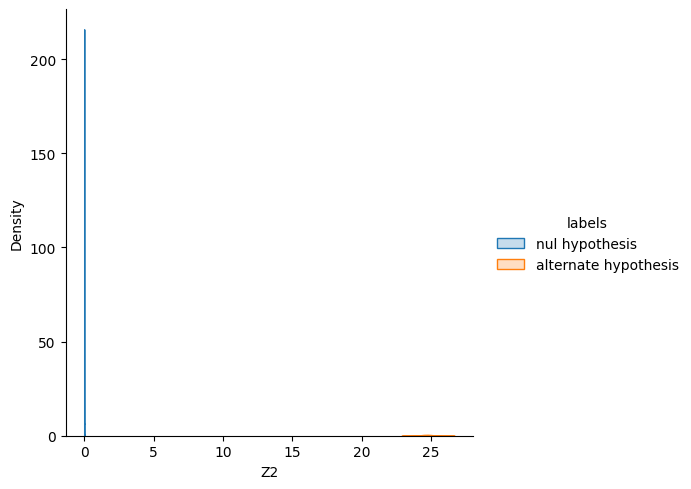

In [2212]:
sns.displot(dis, x="Z2", hue='labels',kind="kde",fill=True)

In [2225]:
stats.chi2.ppf(0.99, df=1)

6.6348966010212145

0.95